# Heat-pump detection by positive-unlabelled (PU) learning

A real smart-meter population comes with no heat-pump labels. Some households may already have
one. A classifier deployed on it can therefore be trained only on **known positives** and an
**unlabelled pool** that may hide more of them. This is the positive-unlabelled (PU) setting.

This notebook trains a heat-pump classifier in that setting on the synthetic GB dataset built in
`04_hp_linkage_lcl_eoh` (`LCL_EoH_join_v6`, training set). It reports results on held-out
households and exports the five α = 2% runs as JSON for the transfer test. The detailed results (sections
8–11) use all five runs at α = 2%, the contamination of the exported models, in the same form as
the EV notebook (`07_ev_pu_classifier`).

**Design:**

| Element | Choice |
|---|---|
| Unit | A household over calendar 2013 |
| Features | The 20 household features of the v6 build (section 3, Table HP_PU_T1), including the temperature-response features (`beta_temp`, `r_hdd`, `consumption_per_hdd`, `delta_cold`, `cov_t_x`) |
| Test split | 30% of households, fixed (seed 42), stratified by label, heating type and dwelling type. Used only for scoring |
| Labelled positives L | 250 heat-pump households from the training split |
| Unlabelled pool U | 1,500 training households: households without a heat pump, plus heat-pump households hidden among them at contamination α |
| Contamination α | 0, 2, 5 and 10% of U |
| Seeds | 5. A seed changes which households form L and U, and the model randomness. The test split never changes |
| Validation | Label-free 5-fold cross-fitting inside L + U. The PU-F1 criterion picks the hyperparameters and the threshold from labelled positives and unlabelled households only. No labelled validation set |
| Methods | PU-bagged XGBoost (main); naive XGBoost, which treats U as negative (baseline); oracle XGBoost, trained on true negatives (ceiling) |

**Two prevalences are kept apart.** The test-set prevalence (~15%) is fixed by the dataset. The
contamination α is the share of hidden heat pumps in the training pool. It is set deliberately,
because the 2013 London pool itself is effectively free of heat pumps.

## 1. Setup

In [1]:
from pathlib import Path
import sys
import textwrap
import time
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from matplotlib.colors import ListedColormap
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))
import pu_common as pc
from hp_feature_defs import SHARE_RENAME

CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
MODEL_DIR = NB_DIR / "HP_classifier"   # the exported heat-pump classifiers, one per seed
for d in (CACHE_DIR, FIG_DIR, TAB_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

V6 = NB_DIR / "LCL_EoH_join_v6"   # created by create_hp_dataset_v6.py
# The five α = 2% runs are exported for notebook 08: one file per seed.
MODEL_PATH = str(MODEL_DIR / "hp_pu_classifier_alpha2_seed{seed}.json")

FEATURES = ["r_hdd", "beta_temp", "delta_cold", "r_ws", "base_summer", "f_zero",
            "am_peak_share", "pm_peak_share", "night_share", "sigma2_delta", "s_winter", "rho_48",
            "d_midday", "cov_t_x", "base_night", "avg_daily_kwh", "cv_daily_kwh",
            "winter_avg_kwh", "summer_avg_kwh", "consumption_per_hdd"]

TEST_FRAC, TEST_SEED = 0.30, 42
N_LABELLED, U_SIZE = 250, 1500
ALPHAS = [0.00, 0.02, 0.05, 0.10]
SEEDS = [0, 1, 2, 3, 4]
EXPORT_ALPHA = 0.02                     # the five runs exported (section 7)
RESTATE_AT = [0.05, 0.02]               # prevalences for restated precision and F1
PLOT_PREVALENCE = 0.02                  # Figures HP_PU4 and HP_PU5: the headline setting, 2% prevalence at α = 2%
HP_TYPES = {"ASHP": "air source", "HT_ASHP": "high-temp. air source", "GSHP": "ground source",
            "Hybrid": "hybrid"}

HEAT_GROUPS = ["Gas", "Mixed", "Electric only", "Other fuel", "Unknown", "No survey response"]
METHODS = ["PU-bagged XGBoost", "Naive XGBoost", "Oracle XGBoost"]

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})

COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}

METHOD_STYLE = {"PU-bagged XGBoost": dict(color=CAT["blue"], marker="o", ls="-"),
                "Naive XGBoost": dict(color=CAT["orange"], marker="s", ls="-"),
                "Oracle XGBoost": dict(color=INK_MUTED, marker="^", ls="--")}


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df

## 2. Data and the fixed test split

The household table of the v6 training set (arm N hosts, E.ON and Warmworks heat pumps) carries
the 20 features, the label, the survey heating type and the dwelling type. The test split is
drawn once, within each combination of label, heating type and dwelling type, so the test set
keeps the training set's mix of confounders. Households with no survey response have no dwelling
type and form their own stratum.

In [3]:
meta = pd.read_parquet(V6 / "hp_metadata.parquet").rename(columns=SHARE_RENAME)
meta["dwelling"] = meta["dwelling_type"].fillna("No survey response")
strata = meta["label"].astype(str) + "|" + meta["heat_group"] + "|" + meta["dwelling"]

rng = np.random.RandomState(TEST_SEED)
test_idx = []
for _, idx in meta.groupby(strata).groups.items():
    idx = np.array(idx)
    test_idx += list(rng.choice(idx, int(round(TEST_FRAC * len(idx))), replace=False))
is_test = meta.index.isin(test_idx)
train, test = meta[~is_test].copy(), meta[is_test].copy()

X_test, y_test = test[FEATURES].to_numpy(float), test["label"].to_numpy()
train_pos = train[train.label == 1]
train_neg = train[train.label == 0]

split = pd.DataFrame({
    "households": [len(train), len(test)],
    "heat-pump households": [int(train.label.sum()), int(test.label.sum())],
    "prevalence": [f"{train.label.mean():.1%}", f"{test.label.mean():.1%}"],
    "electric only": [(train.heat_group == "Electric only").sum(),
                      (test.heat_group == "Electric only").sum()],
    "mixed": [(train.heat_group == "Mixed").sum(), (test.heat_group == "Mixed").sum()],
    "houses": [(train.dwelling == "House").sum(), (test.dwelling == "House").sum()],
}, index=["Training split", "Test split"])
print(f"{len(FEATURES)} features; missing values (XGBoost handles them natively):")
print(meta[FEATURES].isna().sum()[lambda s: s > 0].to_string())
split

20 features; missing values (XGBoost handles them natively):
r_hdd            1
r_ws             1
am_peak_share    1
pm_peak_share    1
night_share      1
rho_48           1
cv_daily_kwh     1


,households,heat-pump households,prevalence,electric only,mixed,houses
Training split,2804,420,15.0%,65,121,762
Test split,1201,179,14.9%,28,53,326


## 3. The 20 household features

Each household is described by 20 features computed from its 2013 half-hourly readings and the
London temperature series (`household_features.py`, run by the v6 build). They fall in four
groups: response to temperature, seasonal level, time-of-day shape and variability. Every
feature is computed from the meter and the weather alone, with no survey or label input, so the
same code can score any GB smart-meter household.

All quantities are per household, over calendar 2013 in GMT. Winter is December, January and
February; summer is June, July and August. Each share of kWh is named `<period>_share`.

**Table HP_PU_T1 - Feature definitions**

| Group | Feature | Definition |
|---|---|---|
| Temperature response | `r_hdd` | Pearson correlation of daily kWh with heating degree-days (base 15.5 °C), over all days |
| Temperature response | `beta_temp` | Least-squares slope of daily kWh on daily mean temperature, over days below 15 °C (kWh per °C; negative when use rises in the cold) |
| Temperature response | `delta_cold` | Mean daily kWh on the household's coldest 5% of winter days minus its winter mean daily kWh |
| Temperature response | `cov_t_x` | Covariance of half-hourly kWh with half-hourly temperature, over winter readings (population covariance) |
| Temperature response | `consumption_per_hdd` | Total kWh on days with any heating demand divided by total heating degree-days |
| Seasonal level | `r_ws` | Winter mean daily kWh divided by summer mean daily kWh |
| Seasonal level | `avg_daily_kwh` | Mean daily kWh over all days |
| Seasonal level | `winter_avg_kwh` | Mean daily kWh over winter days (Dec, Jan, Feb) |
| Seasonal level | `summer_avg_kwh` | Mean daily kWh over summer days (Jun, Jul, Aug) |
| Seasonal level | `base_night` | 10th percentile of half-hourly kWh at 00:30–05:00 in winter minus the same in summer |
| Time of day | `am_peak_share` | Share of winter kWh used 06:00–09:00 |
| Time of day | `pm_peak_share` | Share of winter kWh used 16:00–20:00 |
| Time of day | `night_share` | Share of all kWh used 00:00–07:00, over the whole year |
| Time of day | `d_midday` | Summer mean kWh in the half-hours 07:30–08:00 and 20:30–21:00 minus summer mean kWh 11:30–14:00 |
| Time of day | `base_summer` | 5th percentile of half-hourly kWh at 09:30–16:00 in summer |
| Variability | `sigma2_delta` | Variance of the change between consecutive winter half-hourly readings |
| Variability | `s_winter` | 98th percentile of winter half-hourly kWh divided by the winter median (plus 0.001 kWh) |
| Variability | `rho_48` | Correlation of each half-hourly reading with the reading 48 places earlier (the same half-hour on the previous day), over the whole year |
| Variability | `cv_daily_kwh` | Standard deviation of daily kWh divided by its mean |
| Variability | `f_zero` | Share of half-hourly readings at or below 0.005 kWh |

Two implementation details: `sigma2_delta` and `rho_48` are computed over consecutive
*readings*, so a missing half-hour shifts the lag, and the winter of a calendar year is not
contiguous (February 28 is followed by December 1). Both affect few readings, because every
household has at least 200 complete days in 2013.

The table saved for the thesis adds each feature's median among heat-pump households and among
households without one, in the training split. The SHAP ranking in section 9 shows which of these
differences the classifier relies on.

In [4]:
from hp_feature_defs import FEATURES as FEATURE_DEFS

defs = pd.DataFrame(FEATURE_DEFS).set_index("name")
med = train.groupby("label")[FEATURES].median().T
t0_tab = pd.DataFrame({
    "Group": defs["group"], "Definition": defs["definition"],
    "Median, heat pump": med[1].map(lambda v: f"{v:.3g}"),
    "Median, no heat pump": med[0].map(lambda v: f"{v:.3g}"),
}).loc[[f["name"] for f in FEATURE_DEFS]]
t0_tab.index.name = "Feature"
savetable(t0_tab, "HP_PU_T1_feature_definitions")
t0_tab

saved -> tables/HP_PU_T1_feature_definitions.csv


,Group,Definition,"Median, heat pump","Median, no heat pump"
Feature,,,,
r_hdd,Temperature response,Pearson correlation of daily kWh with heating ...,0.855,0.327
beta_temp,Temperature response,Least-squares slope of daily kWh on daily mean...,-1.6,-0.122
delta_cold,Temperature response,Mean daily kWh on the household's coldest 5% o...,9.29,0.37
cov_t_x,Temperature response,Covariance of half-hourly kWh with half-hourly...,-0.306,0.0156
consumption_per_hdd,Temperature response,Total kWh on days with any heating demand divi...,2.71,1.07
r_ws,Seasonal level,Winter mean daily kWh divided by summer mean d...,2.84,1.3
avg_daily_kwh,Seasonal level,Mean daily kWh over all days,18.9,8.11
winter_avg_kwh,Seasonal level,"Mean daily kWh over winter days (Dec, Jan, Feb)",28,9.25
summer_avg_kwh,Seasonal level,"Mean daily kWh over summer days (Jun, Jul, Aug)",9.72,6.81


## 4. The contamination sweep

For each seed, the training heat pumps are shuffled once. The first 250 are the labelled set L.
The rest form a reserve from which hidden positives are drawn. The households without a heat pump
are shuffled once too. For contamination α, U holds the first α × 1,500 reserve heat pumps and
the first (1 − α) × 1,500 households without one. L stays the same at every α, and each U is
nested in the next, so differences between α values come from contamination alone.

Inside each run:
- **PU-bagged XGBoost.** Each of 25 bags trains on L against a bootstrap sample of U, sized
  1 or 3 times |L|, with tree depth 3 or 5. The four configurations are cross-fitted. The PU-F1
  criterion picks the configuration and the threshold, and also gives π̂, the estimated share of
  heat pumps hidden in U.
- **Naive XGBoost.** L against U as if U were all negative. Its threshold is the best F1 against
  that view, which is all a practitioner without PU correction can do.
- **Oracle XGBoost.** L against the true negatives in U (hidden heat pumps removed). Its
  threshold is the best true-label F1 out of fold. Not achievable in practice: it is the ceiling.

The test households are scored by the mean of the five fold models, so each method's threshold
applies to them without refitting.

In [5]:
def make_run(seed, alpha):
    pos = train_pos.sample(frac=1, random_state=seed)
    neg = train_neg.sample(frac=1, random_state=seed)
    n_hidden = int(round(alpha * U_SIZE))
    assert n_hidden <= len(pos) - N_LABELLED, "not enough reserve heat pumps"
    L, hidden = pos.iloc[:N_LABELLED], pos.iloc[N_LABELLED:N_LABELLED + n_hidden]
    U = pd.concat([hidden, neg.iloc[:U_SIZE - n_hidden]])
    tr = pd.concat([L, U])
    s = np.r_[np.ones(len(L)), np.zeros(len(U))].astype(int)
    return tr, s


t0 = time.time()
rows, main_runs = [], {}
for alpha in ALPHAS:
    for seed in SEEDS:
        tr, s = make_run(seed, alpha)
        keep = alpha == EXPORT_ALPHA
        r, pu = pc.run_one(tr[FEATURES].to_numpy(float), tr["label"].to_numpy(), s,
                           X_test, y_test, seed, keep=keep)
        rows += [{"alpha": alpha, "seed": seed, **x} for x in r]
        if keep:
            main_runs[seed] = pu
        f1 = " | ".join(f"{x['method'].split()[0]} {x['F1']:.3f}" for x in r)
        print(f"alpha {alpha:4.0%} seed {seed}: F1 {f1} | pi_hat {r[0]['pi_hat']:.3f} "
              f"| {time.time() - t0:.0f}s", flush=True)

results = pd.DataFrame(rows)
results.to_parquet(CACHE_DIR / "hp_pu_results.parquet")
print(f"{len(results)} rows -> cache/hp_pu_results.parquet")

alpha   0% seed 0: F1 PU-bagged 0.696 | Naive 0.848 | Oracle 0.848 | pi_hat 0.002 | 16s
alpha   0% seed 1: F1 PU-bagged 0.784 | Naive 0.845 | Oracle 0.845 | pi_hat 0.005 | 29s
alpha   0% seed 2: F1 PU-bagged 0.780 | Naive 0.860 | Oracle 0.860 | pi_hat 0.003 | 43s
alpha   0% seed 3: F1 PU-bagged 0.792 | Naive 0.841 | Oracle 0.841 | pi_hat 0.006 | 57s
alpha   0% seed 4: F1 PU-bagged 0.632 | Naive 0.860 | Oracle 0.860 | pi_hat 0.002 | 71s
alpha   2% seed 0: F1 PU-bagged 0.626 | Naive 0.827 | Oracle 0.845 | pi_hat 0.012 | 88s
alpha   2% seed 1: F1 PU-bagged 0.795 | Naive 0.838 | Oracle 0.862 | pi_hat 0.017 | 103s
alpha   2% seed 2: F1 PU-bagged 0.792 | Naive 0.852 | Oracle 0.843 | pi_hat 0.021 | 121s
alpha   2% seed 3: F1 PU-bagged 0.836 | Naive 0.844 | Oracle 0.847 | pi_hat 0.022 | 137s
alpha   2% seed 4: F1 PU-bagged 0.776 | Naive 0.850 | Oracle 0.864 | pi_hat 0.025 | 153s
alpha   5% seed 0: F1 PU-bagged 0.803 | Naive 0.802 | Oracle 0.850 | pi_hat 0.029 | 171s
alpha   5% seed 1: F1 PU-ba

## 5. Table HP_PU_T2 - Held-out performance against contamination

Mean ± standard deviation over 5 seeds, on the fixed test split. Precision, recall and F1 are at
each method's own threshold. "Best possible F1" uses the best threshold on the test set itself,
so it measures ranking quality, not a usable rule. π̂ is PU bagging's label-free estimate of the
contamination α.

**Prevalence-matched F1.** F1 at the test prevalence (~15%) is not a fair comparison. PU-F1 picks
the threshold that is best for the unlabelled pool, where hidden heat pumps are only α, so it
favours precision. The naive and oracle thresholds are tuned on L against U, about 14% positive,
close to the test prevalence by coincidence. The last two columns therefore restate each run's F1
at 5% and 2% prevalence from its test recall r and false-positive rate FPR, with precision
rπ / (rπ + FPR(1 − π)) at prevalence π, before averaging over seeds. These are the
prevalences a GB deployment would meet, and they put the three methods on the same footing.

In [6]:
for p in RESTATE_AT:
    results[f"F1_at_{p:.0%}"] = [pc.restate(r, f, p)[1]
                                for r, f in zip(results["recall"], results["FPR"])]

COLS = {"ROC_AUC": "ROC-AUC", "PR_AUC": "PR-AUC", "precision": "Precision", "recall": "Recall",
        "F1": "F1", "F1_best_possible": "Best possible F1", "pi_hat": "π̂ (estimated α)",
        **{f"F1_at_{p:.0%}": f"F1 restated at {p:.0%}" for p in RESTATE_AT}}

g = results.groupby(["method", "alpha"])
mean, sd = g[list(COLS)].mean(), g[list(COLS)].std()
t1 = pd.DataFrame(index=mean.index)
for c, lab in COLS.items():
    t1[lab] = [("" if np.isnan(m) else f"{m:.3f} ± {d:.3f}") for m, d in zip(mean[c], sd[c])]
t1 = t1.reset_index()
t1["method"] = pd.Categorical(t1["method"], METHODS, ordered=True)
t1["α"] = (t1.pop("alpha") * 100).map(lambda a: f"{a:.0f}%")
t1 = t1.sort_values(["method", "α"], key=lambda c: c if c.name == "method"
                    else c.str.rstrip("%").astype(float)).set_index(["method", "α"])
savetable(t1, "HP_PU_T2_pu_results_by_alpha")
t1

saved -> tables/HP_PU_T2_pu_results_by_alpha.csv


ROC-AUC         PR-AUC      Precision  \
method            α                                                  
PU-bagged XGBoost 0%   0.981 ± 0.002  0.929 ± 0.004  0.967 ± 0.016   
                  2%   0.980 ± 0.003  0.925 ± 0.008  0.958 ± 0.021   
                  5%   0.980 ± 0.001  0.920 ± 0.005  0.921 ± 0.030   
                  10%  0.978 ± 0.002  0.911 ± 0.011  0.875 ± 0.013   
Naive XGBoost     0%   0.982 ± 0.002  0.934 ± 0.005  0.856 ± 0.033   
                  2%   0.981 ± 0.002  0.923 ± 0.008  0.834 ± 0.025   
                  5%   0.979 ± 0.002  0.914 ± 0.010  0.816 ± 0.025   
                  10%  0.976 ± 0.003  0.894 ± 0.014  0.789 ± 0.036   
Oracle XGBoost    0%   0.982 ± 0.002  0.934 ± 0.005  0.856 ± 0.033   
                  2%   0.982 ± 0.002  0.934 ± 0.005  0.854 ± 0.040   
                  5%   0.982 ± 0.002  0.933 ± 0.005  0.864 ± 0.030   
                  10%  0.982 ± 0.002  0.933 ± 0.006  0.866 ± 0.034   

                              Recall             F1 Best possible F1  \
method            α                                                    
PU-bagged XGBoost 0%   0.600 ± 0.092  0.737 ± 0.071    0.863 ± 0.005   
                  2%   0.645 ± 0.110  0.765 ± 0.081    0.859 ± 0.012   
                  5%   0.728 ± 0.032  0.813 ± 0.014    0.850 ± 0.009   
                  10%  0.772 ± 0.037  0.820 ± 0.017    0.843 ± 0.013   
Naive XGBoost     0%   0.847 ± 0.017  0.851 ± 0.009    0.864 ± 0.007   
                  2%   0.851 ± 0.024  0.842 ± 0.010    0.851 ± 0.015   
                  5%   0.835 ± 0.017  0.825 ± 0.013    0.842 ± 0.010   
                  10%  0.834 ± 0.048  0.809 ± 0.010    0.826 ± 0.016   
Oracle XGBoost    0%   0.847 ± 0.017  0.851 ± 0.009    0.864 ± 0.007   
                  2%   0.853 ± 0.027  0.852 ± 0.010    0.862 ± 0.004   
                  5%   0.841 ± 0.030  0.852 ± 0.006    0.863 ± 0.008   
                  10%  0.839 ± 0.022  0.852 ± 0.008    0.863 ± 0.010   

                      π̂ (estimated α) F1 restated at 5% F1 restated at 2%  
method            α                                                         
PU-bagged XGBoost 0%     0.003 ± 0.002     0.715 ± 0.063     0.671 ± 0.054  
                  2%     0.019 ± 0.005     0.734 ± 0.067     0.675 ± 0.048  
                  5%     0.044 ± 0.009     0.752 ± 0.025     0.645 ± 0.056  
                  10%    0.097 ± 0.017     0.721 ± 0.012     0.568 ± 0.019  
Naive XGBoost     0%                       0.730 ± 0.034     0.554 ± 0.055  
                  2%                       0.705 ± 0.024     0.516 ± 0.037  
                  5%                       0.679 ± 0.027     0.486 ± 0.036  
                  10%                      0.646 ± 0.028     0.446 ± 0.044  
Oracle XGBoost    0%                       0.730 ± 0.034     0.554 ± 0.055  
                  2%                       0.729 ± 0.040     0.553 ± 0.067  
                  5%                       0.737 ± 0.026     0.567 ± 0.049  
                  10%                      0.739 ± 0.034     0.571 ± 0.058

## 6. Figure HP_PU1 - F1 and the prevalence estimate against contamination

saved -> figures/HP_PU1_f1_and_pi_hat_vs_alpha.png


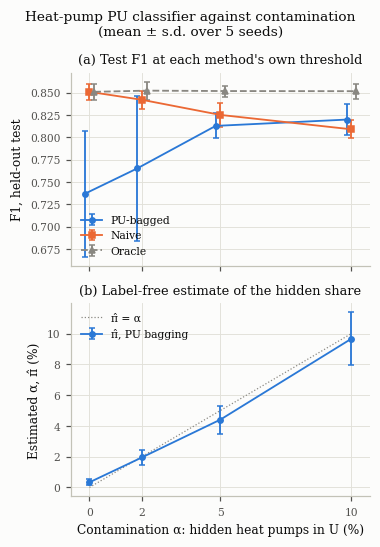

In [7]:
xs = np.array(ALPHAS) * 100
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.0), sharex=True)

    ax = axes[0]
    for k, mth in enumerate(METHODS):
        sub = results[results.method == mth].groupby("alpha")["F1"]
        st = METHOD_STYLE[mth]
        ax.errorbar(xs + (k - 1) * 0.18, sub.mean().values, yerr=sub.std().values,
                    color=st["color"], marker=st["marker"], ls=st["ls"], lw=1.2, ms=3.5,
                    capsize=2, label=mth.replace(" XGBoost", ""))
    ax.set_ylabel("F1, held-out test")
    ax.set_title("(a) Test F1 at each method's own threshold")
    ax.legend(loc="lower left", frameon=False)

    ax = axes[1]
    sub = results[results.method == "PU-bagged XGBoost"].groupby("alpha")["pi_hat"]
    ax.plot([0, 10], [0, 10], color=INK_MUTED, lw=0.8, ls=":", label="π̂ = α")
    ax.errorbar(xs, sub.mean().values * 100, yerr=sub.std().values * 100,
                color=CAT["blue"], marker="o", lw=1.2, ms=3.5, capsize=2, label="π̂, PU bagging")
    ax.set_xlabel("Contamination α: hidden heat pumps in U (%)")
    ax.set_ylabel("Estimated α, π̂ (%)")
    ax.set_title("(b) Label-free estimate of the hidden share")
    ax.set_xticks(xs)
    ax.legend(loc="upper left", frameon=False)

    fig.suptitle("Heat-pump PU classifier against contamination\n(mean ± s.d. over 5 seeds)",
                 fontsize=9)
    fig.tight_layout()
    savefig(fig, "HP_PU1_f1_and_pi_hat_vs_alpha")
    plt.show()

## 7. The exported classifiers

All five PU-bagged runs at α = 2% are exported, one file per seed, for the transfer test
(notebook 08). Each holds 5 folds × 25 bags of XGBoost boosters. Its score is the mean margin over
all boosters, and the threshold is the one PU-F1 chose on its out-of-fold scores, so each file can
be applied to new households unchanged. Each booster is stored in XGBoost's binary format,
base64-encoded inside one JSON file, with the run's settings beside them.

The reload check scores the test households from each file and compares them with the scores
from the run itself.

In [8]:
for seed, pu in main_runs.items():
    model_meta = {
        "technology": "heat_pump", "created": date.today().isoformat(),
        "notebook": "06_hp_pu_classifier",
        "training_data": "LCL_EoH_join_v6 training set (arm N hosts, E.ON + Warmworks heat pumps), "
                         "calendar 2013",
        "unit": "household-year (calendar 2013 window)",
        "method": "PU-bagged XGBoost (Mordelet & Vert 2014), cross-fitted, 5 folds",
        "params": {**pu["params"], "n_bags": pc.N_BAGS, **pc.XGB_BASE},
        "threshold_rule": "PU-F1 (label-free), add-one smoothed",
        "training_alpha": EXPORT_ALPHA, "training_seed": seed,
        "n_labelled": N_LABELLED, "u_size": U_SIZE, "pi_hat_training": pu["pi_hat"],
    }
    path = Path(MODEL_PATH.format(seed=seed))
    doc = pc.export_ensemble(path, pu["models"], FEATURES, pu["threshold"], model_meta)
    err = np.abs(pc.ExportedPUModel(path).decision_function(test) - pu["test"]).max()
    assert err < 1e-4, err
    print(f"seed {seed}: {doc['n_boosters']} boosters -> {path.name} "
          f"({path.stat().st_size / 1e6:.0f} MB), reload matches to {err:.1e}; "
          f"threshold {pu['threshold']:.3f}")

seed 0: 125 boosters -> hp_pu_classifier_alpha2_seed0.json (44 MB), reload matches to 3.8e-06; threshold 3.737
seed 1: 125 boosters -> hp_pu_classifier_alpha2_seed1.json (44 MB), reload matches to 3.2e-06; threshold 3.083
seed 2: 125 boosters -> hp_pu_classifier_alpha2_seed2.json (43 MB), reload matches to 3.1e-06; threshold 3.362
seed 3: 125 boosters -> hp_pu_classifier_alpha2_seed3.json (44 MB), reload matches to 3.1e-06; threshold 2.186
seed 4: 125 boosters -> hp_pu_classifier_alpha2_seed4.json (57 MB), reload matches to 3.5e-06; threshold 3.081


## 8. Table HP_PU_T3 - PU bagging at α = 2% on the held-out test

Two columns, both the mean ± standard deviation over the five α = 2% runs. Each run scores the
test households with its own ensemble and flags them at its own PU-F1 threshold. The ± values are
seed spread, not confidence intervals.
- **All test households**, at the dataset's prevalence.
- **Houses only.** Heat pumps are matched to houses, while many households without one are flats.
  Restricting to houses removes dwelling type as a cue. Only surveyed households have a dwelling
  type, so this column covers fewer households and has a much higher prevalence. Compare its
  ROC-AUC, recall and false-positive rate, not its precision.

Precision and F1 are also **restated** at 5% and 2% prevalence from the recall and the
false-positive rate. That is what this classifier would give in a population where heat pumps
are that common. Recall is also given for each heat-pump type. The last rows give the
false-positive rate within each heating type, among the test households without a heat pump.

In [9]:
def metrics(df, sc, thr):
    # Every row of the table for one run on one set of households, as numbers.
    y, flagged = df["label"].to_numpy(), sc >= thr
    r = pc.score_row(y, sc, thr)
    out = {"ROC-AUC": r["ROC_AUC"], "PR-AUC": r["PR_AUC"], "Recall": r["recall"],
           "False-positive rate": r["FPR"], "Precision, at this prevalence": r["precision"],
           "F1, at this prevalence": r["F1"]}
    for p in RESTATE_AT:
        out[f"Precision, restated at {p:.0%}"], out[f"F1, restated at {p:.0%}"] = \
            pc.restate(r["recall"], r["FPR"], p)
    for code_, name in HP_TYPES.items():
        out[f"Recall, {name}"] = flagged[(y == 1) & (df["hp_type"] == code_).to_numpy()].mean()
    for gname in HEAT_GROUPS:
        m = (y == 0) & (df["heat_group"] == gname).to_numpy()
        out[f"FPR, {gname}"] = flagged[m].mean() if m.any() else np.nan
    return out


def counts(df):
    # The n behind each by-type and by-heating-group row.
    y = df["label"]
    return {**{f"Recall, {name}": ((y == 1) & (df["hp_type"] == c)).sum() for c, name in HP_TYPES.items()},
            **{f"FPR, {g}": ((y == 0) & (df["heat_group"] == g)).sum() for g in HEAT_GROUPS}}


def column(df, values, sd=None):
    n = counts(df)
    out = {"Households": f"{len(df):,}", "  with a heat pump": f"{int(df['label'].sum()):,}",
           "  prevalence": f"{df['label'].mean():.1%}"}
    for k, v in values.items():
        if np.isnan(v):
            out[k] = "–"
            continue
        out[k] = f"{v:.3f}" + ("" if sd is None else f" ± {sd[k]:.3f}") \
            + (f" (n={n[k]})" if k in n else "")
    return out


is_house = (test.dwelling == "House").to_numpy()
houses = test[is_house].copy()
per_seed, per_seed_houses = {}, {}
for seed, run in main_runs.items():
    test[f"score_{seed}"], test[f"naive_{seed}"] = run["test"], run["naive_test"]
    per_seed[seed] = metrics(test, run["test"], run["threshold"])
    per_seed_houses[seed] = metrics(houses, run["test"][is_house], run["threshold"])
    print(f"seed {seed}: configuration {run['params']}, threshold {run['threshold']:.3f}, "
          f"pi_hat {run['pi_hat']:.3f} (true {EXPORT_ALPHA:.0%})")
per_seed = pd.DataFrame(per_seed).T.rename_axis("seed")
per_seed_houses = pd.DataFrame(per_seed_houses).T
savetable(per_seed.round(4), f"HP_PU_S_alpha{EXPORT_ALPHA * 100:.0f}_by_seed")

t2 = pd.DataFrame({
    f"All 5 runs at α = {EXPORT_ALPHA:.0%}, all test households": column(test, per_seed.mean(), per_seed.std()),
    f"All 5 runs at α = {EXPORT_ALPHA:.0%}, houses only": column(houses, per_seed_houses.mean(),
                                                               per_seed_houses.std()),
})
savetable(t2, "HP_PU_T3_exported_classifier_test")
t2

seed 0: configuration {'max_depth': 3, 'u_ratio': 3}, threshold 3.737, pi_hat 0.012 (true 2%)
seed 1: configuration {'max_depth': 5, 'u_ratio': 1}, threshold 3.083, pi_hat 0.017 (true 2%)
seed 2: configuration {'max_depth': 5, 'u_ratio': 1}, threshold 3.362, pi_hat 0.021 (true 2%)
seed 3: configuration {'max_depth': 3, 'u_ratio': 3}, threshold 2.186, pi_hat 0.022 (true 2%)
seed 4: configuration {'max_depth': 5, 'u_ratio': 3}, threshold 3.081, pi_hat 0.025 (true 2%)
saved -> tables/HP_PU_S_alpha2_by_seed.csv
saved -> tables/HP_PU_T3_exported_classifier_test.csv


,"All 5 runs at α = 2%, all test households","All 5 runs at α = 2%, houses only"
Households,"1,201",326
with a heat pump,179,170
prevalence,14.9%,52.1%
ROC-AUC,0.980 ± 0.003,0.981 ± 0.002
PR-AUC,0.925 ± 0.008,0.983 ± 0.002
Recall,0.645 ± 0.110,0.665 ± 0.111
False-positive rate,0.005 ± 0.003,0.005 ± 0.003
"Precision, at this prevalence",0.958 ± 0.021,0.993 ± 0.004
"F1, at this prevalence",0.765 ± 0.081,0.792 ± 0.085
"Precision, restated at 5%",0.875 ± 0.059,0.883 ± 0.066


## 9. Figure HP_PU2 - Which features the classifier uses

Mean absolute SHAP value of each feature on the test households. SHAP values are additive in the
margin, so an ensemble's values are the mean over its boosters. The bars are the mean over the
five α = 2% runs and the whiskers their standard deviation.

saved -> tables/HP_PU_S_shap_importance.csv
saved -> figures/HP_PU2_shap_top10.png


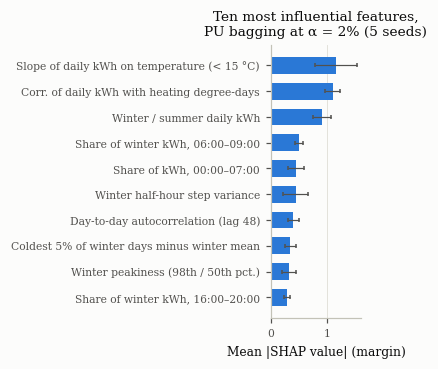

In [10]:
FEATURE_LABELS = {
    "r_hdd": "Corr. of daily kWh with heating degree-days",
    "beta_temp": "Slope of daily kWh on temperature (< 15 °C)",
    "delta_cold": "Coldest 5% of winter days minus winter mean",
    "r_ws": "Winter / summer daily kWh",
    "base_summer": "Summer daytime base load (5th pct.)",
    "f_zero": "Share of zero half-hours",
    "am_peak_share": "Share of winter kWh, 06:00–09:00",
    "pm_peak_share": "Share of winter kWh, 16:00–20:00",
    "night_share": "Share of kWh, 00:00–07:00",
    "sigma2_delta": "Winter half-hour step variance",
    "s_winter": "Winter peakiness (98th / 50th pct.)",
    "rho_48": "Day-to-day autocorrelation (lag 48)",
    "d_midday": "Summer shoulder minus midday load",
    "cov_t_x": "Winter covariance of load and temperature",
    "base_night": "Night base load, winter minus summer",
    "avg_daily_kwh": "Mean daily kWh",
    "cv_daily_kwh": "Coefficient of variation of daily kWh",
    "winter_avg_kwh": "Winter mean daily kWh",
    "summer_avg_kwh": "Summer mean daily kWh",
    "consumption_per_hdd": "kWh per heating degree-day",
}

Xt = test[FEATURES].to_numpy(float)
imp_seed = {}
for seed, run in main_runs.items():
    boosters = [m.get_booster() for fm in run["models"] for m in fm.models]
    sv = np.zeros(Xt.shape)
    for b in boosters:
        sv += shap.TreeExplainer(b).shap_values(Xt) / len(boosters)
    imp_seed[seed] = np.abs(sv).mean(axis=0)
imp_seed = pd.DataFrame(imp_seed, index=FEATURES)
imp = pd.DataFrame({"mean_abs_shap": imp_seed.mean(axis=1), "sd_over_seeds": imp_seed.std(axis=1)})
imp = imp.sort_values("mean_abs_shap", ascending=False)
savetable(imp, "HP_PU_S_shap_importance")

top = imp.head(10)[::-1]
with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 3.4))
    ax.barh([FEATURE_LABELS[f] for f in top.index], top.mean_abs_shap, xerr=top.sd_over_seeds,
            color=CAT["blue"], height=0.65, error_kw=dict(ecolor=INK_SECONDARY, lw=0.8, capsize=1.5))
    ax.set_xlabel("Mean |SHAP value| (margin)")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"Ten most influential features,\nPU bagging at α = {EXPORT_ALPHA:.0%} (5 seeds)", fontsize=9)
    fig.tight_layout()
    savefig(fig, "HP_PU2_shap_top10")
    plt.show()

### Figure HP_PU3 - Pairwise plot of the five most influential features

The five features with the largest mean |SHAP| on the same test households, by label, so the
pattern behind the SHAP ranking can be seen directly.
- **Below the diagonal:** each household as a point. Households without a heat pump are drawn
  first, so heat-pump households sit on top.
- **On the diagonal:** the distribution of each feature within each class, as densities, so the two
  classes compare despite the 15% prevalence. The y-axis is scaled to the heat-pump curve, so a
  narrow peak among households without one can run off the top.
- **Above the diagonal:** Spearman's rank correlation within each class, over households where both
  features are defined.

Axes stop at the 0.5th and 99.5th percentiles, which leaves out a few extreme points (the
winter/summer ratio runs far above the axis for a few homes with almost no summer use).

saved -> figures/HP_PU3_pairplot_top5.png


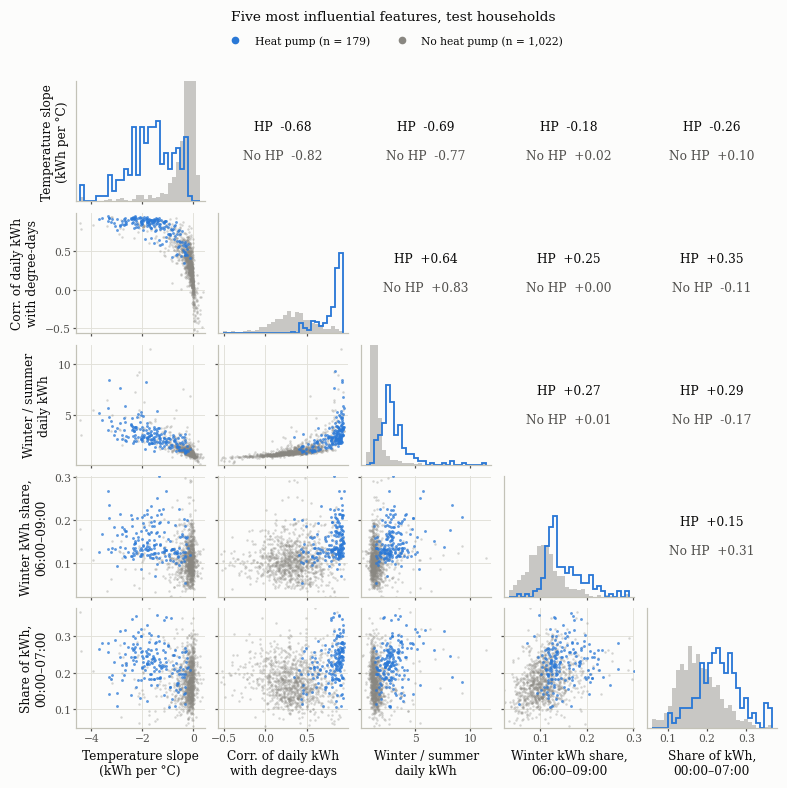

In [11]:
FULL_WIDTH = 7.2
top5 = list(imp.index[:5])
P = test[top5]
is_hp = test["label"].to_numpy() == 1
limits = {f: (P[f].quantile(0.005), P[f].quantile(0.995)) for f in top5}
pad = {f: 0.04 * (hi - lo) for f, (lo, hi) in limits.items()}
PAIR_LABELS = {"r_hdd": "Corr. of daily kWh\nwith degree-days", "r_ws": "Winter / summer\ndaily kWh",
               "am_peak_share": "Winter kWh share,\n06:00–09:00",
               "beta_temp": "Temperature slope\n(kWh per °C)",
               "rho_48": "Day-to-day\nautocorrelation"}
lab = lambda f: PAIR_LABELS.get(f, textwrap.fill(FEATURE_LABELS[f], 18))
n = len(top5)

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(n, n, figsize=(FULL_WIDTH, FULL_WIDTH))
    for i, fy in enumerate(top5):
        for j, fx in enumerate(top5):
            ax = axes[i, j]
            if i < j:
                ax.axis("off")
                rho_hp = test.loc[is_hp, [fx, fy]].corr("spearman").iloc[0, 1]
                rho_no = test.loc[~is_hp, [fx, fy]].corr("spearman").iloc[0, 1]
                ax.text(0.5, 0.62, f"HP  {rho_hp:+.2f}", ha="center", va="center",
                        transform=ax.transAxes)
                ax.text(0.5, 0.38, f"No HP  {rho_no:+.2f}", ha="center", va="center",
                        transform=ax.transAxes, color=INK_SECONDARY)
                continue
            if i == j:
                bins = np.linspace(*limits[fx], 31)
                x = P[fx].clip(*limits[fx])
                ax.hist(x[~is_hp].dropna(), bins=bins, density=True, histtype="stepfilled",
                        color=INK_MUTED, alpha=0.45, lw=0)
                d = ax.hist(x[is_hp].dropna(), bins=bins, density=True, histtype="step",
                            color=CAT["blue"], lw=1.2)[0]
                ax.set_ylim(0, d.max() * 1.5)
                ax.set_yticks([])
                ax.grid(False)
            else:
                ax.scatter(P.loc[~is_hp, fx], P.loc[~is_hp, fy], s=2.5, color=INK_MUTED,
                           alpha=0.35, lw=0)
                ax.scatter(P.loc[is_hp, fx], P.loc[is_hp, fy], s=3.5, color=CAT["blue"],
                           alpha=0.75, lw=0)
                ax.set_ylim(limits[fy][0] - pad[fy], limits[fy][1] + pad[fy])
            ax.set_xlim(limits[fx][0] - pad[fx], limits[fx][1] + pad[fx])
            ax.tick_params(length=2, pad=1)
            ax.locator_params(nbins=3)
            if i < n - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(lab(fx))
            if j == 0:
                ax.set_ylabel(lab(fy))
            elif i != j:
                ax.set_yticklabels([])
    handles = [plt.Line2D([], [], marker="o", ls="none", ms=4, color=CAT["blue"],
                          label=f"Heat pump (n = {is_hp.sum():,})"),
               plt.Line2D([], [], marker="o", ls="none", ms=4, color=INK_MUTED,
                          label=f"No heat pump (n = {(~is_hp).sum():,})")]
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 0.965))
    fig.suptitle("Five most influential features, test households", fontsize=9, y=0.985)
    fig.tight_layout(rect=(0, 0, 1, 0.945), h_pad=0.4, w_pad=0.4)
    savefig(fig, "HP_PU3_pairplot_top5")
    plt.show()

## 10. Figures HP_PU4 and HP_PU4b - ROC and precision–recall curves, with the naive baseline

Thin lines are the curves of the five α = 2% runs on the test households. Markers are each
method's mean operating point (each run's own threshold; whiskers ± 1 s.d. over seeds). The naive
model, trained on the same L and U, shows what the same ranking gives without the PU threshold.
The two figures share panel (a) and differ in the prevalence of panel (b).
- **(a) ROC.** True-positive rate against false-positive rate. Neither depends on prevalence, so
  the test set gives them directly.
- **(b) Precision–recall.** Precision does depend on prevalence. In **HP_PU4** each curve is
  restated at 2%, the headline setting (α = 2%, 2% prevalence), from each threshold's recall and
  false-positive rate. In **HP_PU4b** it is at the test set's own prevalence (14.9%), as observed.
  The dotted line is a classifier that flags at random.

saved -> figures/HP_PU4_roc_pr.png


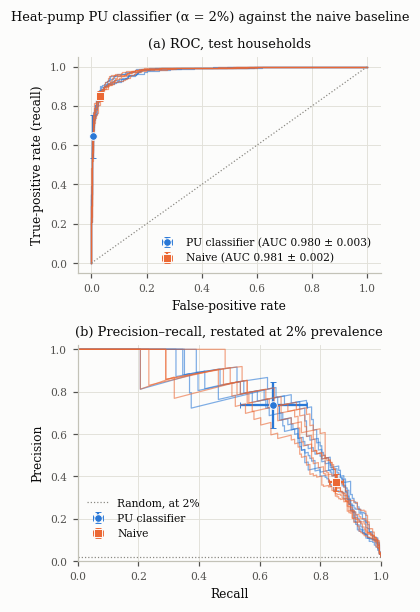

saved -> figures/HP_PU4b_roc_pr_test_prevalence.png


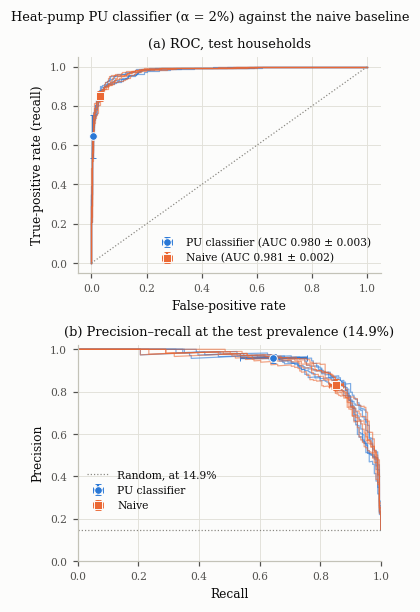

PU classifier: recall 0.645, FPR 0.0053, precision at 2% 0.713, at 14.9% 0.955
Naive: recall 0.851, FPR 0.0299, precision at 2% 0.367, at 14.9% 0.833


In [12]:
TEST_PREVALENCE = y_test.mean()
hp_mask = y_test == 1
COMPARE = {"PU classifier": ("score", "threshold", METHOD_STYLE["PU-bagged XGBoost"]),
           "Naive": ("naive", "naive_threshold", METHOD_STYLE["Naive XGBoost"])}
pts = {name: pd.DataFrame([{"fpr": (test[f"{col}_{s}"] >= run[thr_key])[~hp_mask].mean(),
                            "recall": (test[f"{col}_{s}"] >= run[thr_key])[hp_mask].mean()}
                           for s, run in main_runs.items()])
       for name, (col, thr_key, _) in COMPARE.items()}


def roc_pr_figure(pi, b_title, name):
    with plt.rc_context(COLUMN_RC):
        fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.6))
        for cname, (col, _, st) in COMPARE.items():
            aucs = []
            for seed in main_runs:
                fpr_c, tpr_c, _t = roc_curve(y_test, test[f"{col}_{seed}"])
                aucs.append(roc_auc_score(y_test, test[f"{col}_{seed}"]))
                with np.errstate(invalid="ignore", divide="ignore"):
                    prec_pi = np.where(tpr_c > 0, tpr_c * pi / (tpr_c * pi + fpr_c * (1 - pi)), 1.0)
                axes[0].plot(fpr_c, tpr_c, color=st["color"], lw=0.8, alpha=0.6)
                axes[1].plot(tpr_c, prec_pi, color=st["color"], lw=0.8, alpha=0.6)
            p = pts[cname]
            prec = np.array([pc.restate(r, f, pi)[0] for r, f in zip(p.recall, p.fpr)])
            axes[0].errorbar(p.fpr.mean(), p.recall.mean(), xerr=p.fpr.std(), yerr=p.recall.std(),
                             marker=st["marker"], color=st["color"], ms=5, ls="none", mec="white",
                             mew=0.6, capsize=2,
                             label=f"{cname} (AUC {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f})")
            axes[1].errorbar(p.recall.mean(), prec.mean(), xerr=p.recall.std(), yerr=prec.std(ddof=1),
                             marker=st["marker"], color=st["color"], ms=5, ls="none", mec="white",
                             mew=0.6, capsize=2, label=cname)

        ax = axes[0]
        ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=0.8, ls=":")
        ax.set_xlabel("False-positive rate")
        ax.set_ylabel("True-positive rate (recall)")
        ax.set_title("(a) ROC, test households")
        ax.legend(loc="lower right", frameon=False)

        ax = axes[1]
        ax.axhline(pi, color=INK_MUTED, lw=0.8, ls=":", label=f"Random, at {pi:.1%}".replace(".0%", "%"))
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.set_ylim(0, 1.02)
        ax.set_xlim(0, 1.0)
        ax.set_title(b_title)
        ax.legend(loc="lower left", bbox_to_anchor=(0, max(0.06, pi + 0.04)), frameon=False)   # above the random line
        fig.suptitle(f"Heat-pump PU classifier (α = {EXPORT_ALPHA:.0%}) against the naive baseline",
                     fontsize=8.5)
        fig.tight_layout()
        savefig(fig, name)
        plt.show()


roc_pr_figure(PLOT_PREVALENCE, f"(b) Precision–recall, restated at {PLOT_PREVALENCE:.0%} prevalence",
              "HP_PU4_roc_pr")
roc_pr_figure(TEST_PREVALENCE, f"(b) Precision–recall at the test prevalence ({TEST_PREVALENCE:.1%})",
              "HP_PU4b_roc_pr_test_prevalence")

ops = {name: (p.fpr.mean(), p.recall.mean()) for name, p in pts.items()}
for name, (fp, r) in ops.items():
    print(f"{name}: recall {r:.3f}, FPR {fp:.4f}, precision at {PLOT_PREVALENCE:.0%} "
          f"{pc.restate(r, fp, PLOT_PREVALENCE)[0]:.3f}, at {TEST_PREVALENCE:.1%} "
          f"{pc.restate(r, fp, TEST_PREVALENCE)[0]:.3f}")

## 11. Figure HP_PU5 - Confusion matrices per 1,000 households at 2% prevalence

A confusion matrix's counts depend on prevalence, so the test set's counts (15% heat pumps) would
not describe a deployment. Each matrix instead shows the **expected counts in 1,000 households of
which 2% (20) have a heat pump**, the headline setting, from each method's test recall and
false-positive rate: true positives = 20 × recall, false positives = 980 × false-positive rate. For both methods,
recall and the false-positive rate are the means over the five α = 2% runs.

saved -> figures/HP_PU5_confusion_per_1000.png


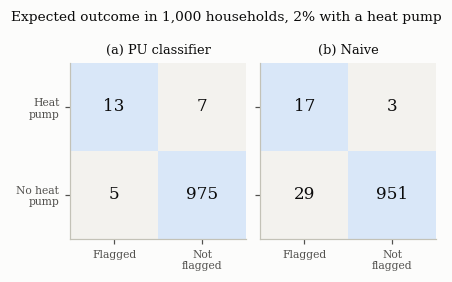

In [13]:
N_HH = 1000
pi = PLOT_PREVALENCE   # Figure HP_PU5 stays at the 2% headline setting
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(1, 2, figsize=(3.9, 2.45), layout="constrained")
    for ax, (name, (fp, r)), tag in zip(axes, ops.items(), "ab"):
        npos, nneg = N_HH * pi, N_HH * (1 - pi)
        cm = np.array([[npos * r, npos * (1 - r)], [nneg * fp, nneg * (1 - fp)]])
        ax.imshow([[1, 0], [0, 1]], cmap=ListedColormap(["#f3f2ee", "#d9e7f8"]),
                  vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=11,
                        color=INK_PRIMARY)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Flagged", "Not\nflagged"], fontsize=7)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["Heat\npump", "No heat\npump"] if tag == "a" else ["", ""])
        ax.grid(False)
        ax.set_title(f"({tag}) {name}", fontsize=8.5)
    fig.suptitle(f"Expected outcome in {N_HH:,} households, {pi:.0%} with a heat pump", fontsize=9)
    savefig(fig, "HP_PU5_confusion_per_1000")
    plt.show()

## 12. Notes and limitations

- Contamination is simulated. The London pool has almost no heat pumps, so the hidden positives
  are constructed, and real hidden heat pumps could differ from the EoH cohort.
- PU learning assumes the labelled heat pumps are a random sample of all heat pumps. That holds
  here by construction, but heat pumps from a scheme or register may be newer or in particular
  kinds of home.
- Test prevalence (about 15%) is well above GB's, so precision and F1 are also restated at 5% and
  2% (Table HP_PU_T3).
- Dwelling type is linked to the label, so Table HP_PU_T3 also gives results for houses alone.
- π̂ is an upper bound and is smoothed, so it stays above zero even at α = 0.
- All five α = 2% runs are exported, and the tables and figures average them.
- The ± values are the spread over five seeds, not confidence intervals, and the test split is
  fixed.
- The naive model ranks households almost the same way as PU bagging, so the difference between
  them comes from the threshold.
- Recall for ground-source heat pumps rests on small counts.